# Neuro-Gated Chess: the model and the bot

**AIML minor-degree mini project** · Om Kulkarni, Rohan Bhide, Shaunak Save, Parth Kamble

A chess agent with a fast **System 1** (the pre-trained LayaChess model scores every legal move) and a slow **System 2** (our PUCT tree search over a value network we trained). A **gate** decides when to search; from V2 on, a **material safety net** checks every move before it is played.

This notebook walks through the whole system in the order a move is made, then reproduces the results of the three versions:

1. Data: Lichess Elite games → positions → 18-plane encoding
2. The value network (the model we trained): architecture, training, evaluation
3. System 1: LayaChess and its confidence
4. System 2: PUCT search
5. The V2 safety net
6. The gates: V1 confidence, V2 sharp-position rules, V3 learned gate
7. The full agent playing a game against Stockfish
8. Results of V1, V2 and V3

Run it from the project's `notebooks/` folder (or the repo root) inside the project's virtual environment. It uses the project's own code in `src/`; every function shown here is the one the experiments used. It needs the GPU, LayaChess, Stockfish, the processed data and the trained checkpoints that exist on the experiment laptop. Without training (`TRAIN = False`) a full run takes roughly 10–15 minutes.

In [1]:
import os, sys, json, math, time, subprocess
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import chess
import chess.svg
from IPython.display import SVG, HTML, display

from src.utils import load_config, load_gate_config, resolve, seed_everything, pick_device

CFG = load_config("configs/v3.yaml")      # V3 config = V2 settings + the V3 additions (generated by scripts/make_v2_config.py)
DEVICE = pick_device("cuda")
seed_everything(CFG["seed"])
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def show(board, arrows=(), size=300):
    display(SVG(chess.svg.board(board, arrows=list(arrows), size=size)))

print("repo:", ROOT)
print("device:", DEVICE, "| torch", torch.__version__, "| python-chess", chess.__version__)
print("prior temperature (search):", CFG["v2"]["prior_temperature"], " <- must be 0.1")

repo: /home/burner/Chess/neuro-gated-chess-build/neuro-gated-chess
device: cuda | torch 2.14.1+cu130 | python-chess 1.11.2
prior temperature (search): 0.1  <- must be 0.1


## 1. Data: from games to numbers

We use the **Lichess Elite** database (games between players rated 2400+ and 2200+), downloaded as parquet from Hugging Face and converted to one PGN file per month (`scripts/convert_hf_elite.py`). Train, validation and test are split **by month**, so no game appears in two splits:

| Months | Use |
|---|---|
| 2025-04 … 2025-09 | value-net training (500,000 positions) |
| 2025-10 | validation: every tuning decision |
| 2025-11 / 2025-03 / 2025-02 | test sets of V1 / V2 / V3 (each month untouched until its test) |

Below: one real game from the raw PGN files, and one position sampled from it the way the training set was built (`src/model/dataset.py`).

PGN files: ['lichess_elite_2025-02.pgn (2025-02)', 'lichess_elite_2025-03.pgn (2025-03)', 'lichess_elite_2025-04.pgn (2025-04)', 'lichess_elite_2025-05.pgn (2025-05)', 'lichess_elite_2025-06.pgn (2025-06)', 'lichess_elite_2025-07.pgn (2025-07)', 'lichess_elite_2025-08.pgn (2025-08)', 'lichess_elite_2025-09.pgn (2025-09)', 'lichess_elite_2025-10.pgn (2025-10)', 'lichess_elite_2025-11.pgn (2025-11)']

Harald_Blatand (2518) vs Misterchess64 (2571), 0-1, 2025.11.01
sampled position at ply 68: 2r2k2/1rq2p2/4p1p1/2p1P3/P1PpBP1p/4nQ1P/2P3P1/1R5K w - - 0 35


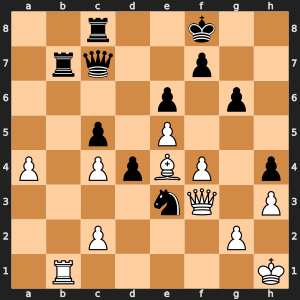

In [2]:
from src.model.dataset import iter_games, keep_game, sample_positions, month_of

raw_files = sorted(resolve(CFG["data"]["raw_dir"]).glob("lichess_elite_*.pgn"))
print("PGN files:", [f"{p.name} ({month_of(p)})" for p in raw_files])

game = None
if raw_files:
    game = next(g for g in iter_games(raw_files[-1]) if keep_game(g, CFG["data"]["min_plies"], True))
    h = game.headers
    print(f"\n{h.get('White')} ({h.get('WhiteElo')}) vs {h.get('Black')} ({h.get('BlackElo')}), {h.get('Result')}, {h.get('Date')}")
    ply, board = sample_positions(game, 1, 20, np.random.default_rng(0))[0]
    print(f"sampled position at ply {ply}:", board.fen())
    show(board)
else:
    board = chess.Board("r1bqkbnr/pppp1ppp/2n5/4p3/2B1P3/5N2/PPPP1PPP/RNBQK2R b KQkq - 3 3")
    print("no raw PGN files found; using an example position")
    show(board)

### Encoding a board as 18 planes

`board_to_planes` turns a position into an 18 × 8 × 8 array of 0s and 1s: 12 piece planes (P N B R Q K for White, p n b r q k for Black), side to move, four castling rights, and the en-passant square. The original design had only the 12 piece planes, so the network could not tell whose move it was.

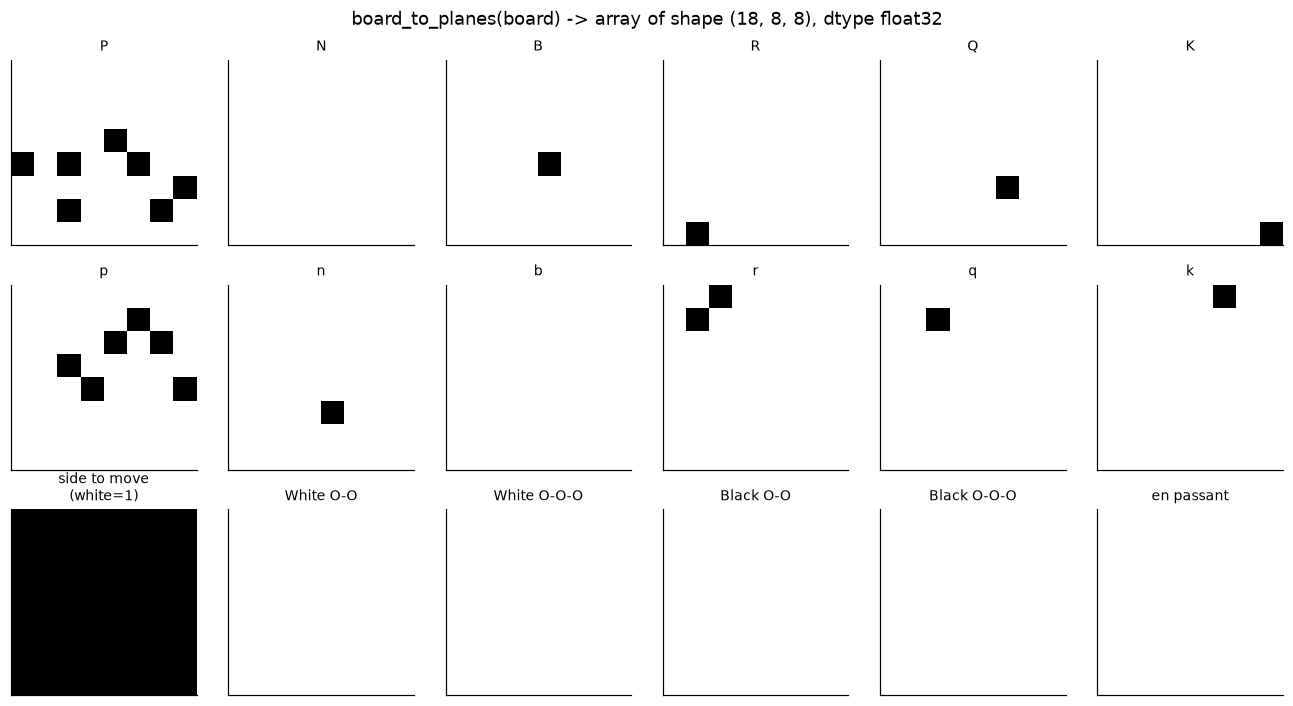

In [3]:
from src.model.encoding import board_to_planes, PIECE_ORDER

planes = board_to_planes(board)
names = list(PIECE_ORDER) + ["side to move\n(white=1)", "White O-O", "White O-O-O", "Black O-O", "Black O-O-O", "en passant"]
fig, axes = plt.subplots(3, 6, figsize=(12, 6.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(planes[i][::-1], cmap="Greys", vmin=0, vmax=1)      # rank 8 at the top
    ax.set_title(names[i], fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"board_to_planes(board) -> array of shape {planes.shape}, dtype {planes.dtype}")
plt.tight_layout(); plt.show()

### The training set

`scripts/prepare_data.py` sampled up to 8 positions per game (500k training positions) and stored them bit-packed (144 bytes per position). For V2, `scripts/label_sf.py` added a Stockfish evaluation (10,000 nodes) to every position, and the label became a blend:

$$y = 0.5 \cdot \text{game result} + 0.5 \cdot \tanh(\text{Stockfish cp} / 400)$$

The game result alone (+1 / 0 / −1, from White's side) is noisy: a good position can still be lost later in the game.

files: /home/burner/Chess/neuro-gated-chess-build/neuro-gated-chess/data/processed_v2
train: {'planes': (500000, 144), 'y': (500000,), 'fens': (500000,), 'game_ids': (500000,), 'plies': (500000,), 'sf_cp_white': (500000,)}
val:   {'planes': (20002, 144), 'y': (20002,), 'fens': (20002,), 'game_ids': (20002,), 'plies': (20002,), 'sf_cp_white': (20002,)}


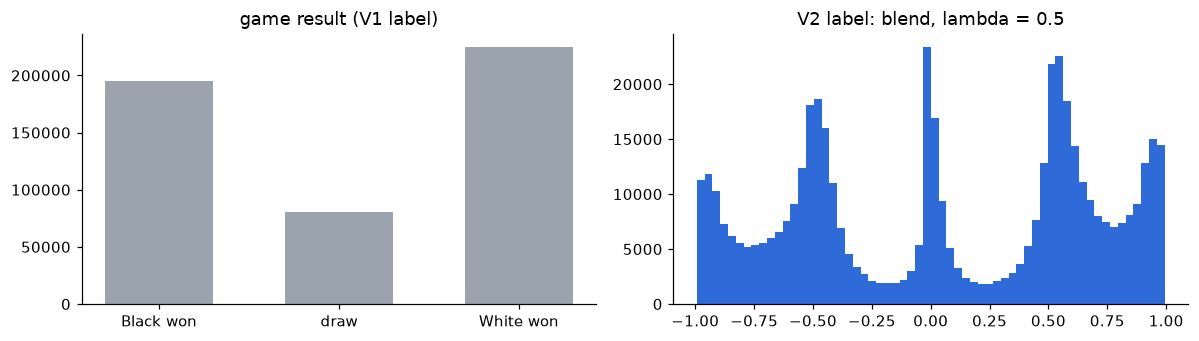

In [4]:
from src.model.dataset import load_npz, blend_labels

proc = resolve(CFG["data"]["processed_dir"])
tr, va = load_npz(proc / "train.npz"), load_npz(proc / "val.npz")
print("files:", proc)
print("train:", {k: v.shape for k, v in tr.items()})
print("val:  ", {k: v.shape for k, v in va.items()})

def labels(d):
    z = d["y"].astype(np.float32)
    if CFG["label"]["mode"] == "blend" and "sf_cp_white" in d:
        return blend_labels(z, d["sf_cp_white"], CFG["label"]["blend_lambda"]).astype(np.float32)
    return z

y_tr, y_va = labels(tr), labels(va)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(tr["y"], bins=[-1.5, -0.5, 0.5, 1.5], rwidth=0.6, color="#9AA3AE")
ax[0].set_xticks([-1, 0, 1], ["Black won", "draw", "White won"]); ax[0].set_title("game result (V1 label)")
ax[1].hist(y_tr, bins=60, color="#2F6BD8"); ax[1].set_title(f"V2 label: blend, lambda = {CFG['label']['blend_lambda']}")
plt.tight_layout(); plt.show()

## 2. The value network (the model we trained)

`ValueCNN` ("ValueNet-6x128", `src/model/architecture.py`) maps the 18 planes to one number in [−1, +1], from White's side:

- **Stem:** 3×3 conv, 18 → 128 channels, batch norm, ReLU
- **Body:** 6 residual blocks (conv → BN → ReLU → conv → BN, plus the skip connection, then ReLU)
- **Head:** 1×1 conv to 32 channels → flatten (2048) → fully connected 256 → **LeakyReLU** (V2; ReLU in V1) → fully connected 1 → tanh

The head does **not** average-pool the board to one number (the original design did), which would throw away where the pieces are. V1's ReLU in the 256-unit layer "died" on 9.2% of test positions and gave a constant output; V2 switched to LeakyReLU (checked in section 2.3).

In [5]:
from src.model.architecture import model_from_config, load_checkpoint, save_checkpoint, make_value_fn

net = model_from_config(CFG)
print(net)
print(f"\nparameters: {sum(p.numel() for p in net.parameters()):,}")
x = torch.from_numpy(board_to_planes(board)).unsqueeze(0)
with torch.no_grad():
    y = net.eval()(x)
print("input", tuple(x.shape), "-> output", tuple(y.shape), "(untrained:", round(y.item(), 4), ")")

ValueCNN(
  (stem): Sequential(
    (0): Conv2d(18, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (body): Sequential(
    (0): ResBlock(
      (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): ResBlock(
      (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False

### 2.1 Training

The same loop as `src/model/train.py`: MSE loss, AdamW (lr 1e-3, weight decay 1e-4 in V2), cosine learning-rate schedule, batch 256, keep the checkpoint with the best validation loss. It first prints the **constant-predictor baseline** (always predict the mean label), which the network has to beat.

`TRAIN = False` (default) loads the trained V2 checkpoint the experiments used. `TRAIN = True` trains a fresh network into a **separate** file, `notebook_model.pt`, so the frozen checkpoints are never overwritten. A full run was 20 epochs on 500k positions at about 50 s per epoch; set `MAX_TRAIN` / `EPOCHS` smaller for a quick demonstration.

In [6]:
from torch.utils.data import DataLoader
from src.model.dataset import PositionDataset
from src.model.encoding import unpack_planes

TRAIN = True    
EPOCHS, MAX_TRAIN = 3, 100_000
NB_CKPT = resolve("src/model/checkpoints/notebook_model.pt")
FROZEN_CKPT = resolve(CFG["model"]["checkpoint"])             # best_model_v2.pt

@torch.no_grad()
def predict(model, packed, bs=2048):
    model.eval(); out = []
    for i in range(0, len(packed), bs):
        out.append(model(torch.from_numpy(unpack_planes(packed[i:i + bs])).to(DEVICE)).squeeze(1).float().cpu().numpy())
    return np.concatenate(out)

baseline = float(np.mean((y_va - y_tr.mean()) ** 2))
print(f"constant-predictor baseline val MSE: {baseline:.4f}")

history = []
if TRAIN:
    tc = CFG["train"]
    ds = PositionDataset(tr["planes"][:MAX_TRAIN], y_tr[:MAX_TRAIN], color_flip=CFG["model"]["color_flip_augmentation"], seed=CFG["seed"])
    dl = DataLoader(ds, batch_size=tc["batch_size"], shuffle=True, num_workers=2, pin_memory=DEVICE.startswith("cuda"), drop_last=True)
    model = model_from_config(CFG).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=tc["lr"], weight_decay=tc["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    best = float("inf")
    for epoch in range(1, EPOCHS + 1):
        model.train(); t0, tot, n = time.time(), 0.0, 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            loss = torch.nn.functional.mse_loss(model(xb), yb)
            loss.backward(); opt.step()
            tot += float(loss) * len(xb); n += len(xb)
        sched.step()
        val_loss = float(np.mean((predict(model, va["planes"]) - y_va) ** 2))
        history.append({"epoch": epoch, "train_loss": tot / n, "val_loss": val_loss})
        print(f"epoch {epoch}: train {tot / n:.4f}  val {val_loss:.4f}  ({time.time() - t0:.0f}s)")
        if val_loss < best:
            best = val_loss; save_checkpoint(model, NB_CKPT, {"epoch": epoch, "val_loss": val_loss})
    value_net = load_checkpoint(NB_CKPT, DEVICE)
else:
    value_net = load_checkpoint(FROZEN_CKPT, DEVICE)
    print("loaded the frozen V2 checkpoint:", FROZEN_CKPT.name)

constant-predictor baseline val MSE: 0.3721


/tmp/ipykernel_2758/3602905559.py:36: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  tot += float(loss) * len(xb); n += len(xb)


epoch 1: train 0.3728  val 0.3276  (11s)


epoch 2: train 0.3065  val 0.2983  (10s)


epoch 3: train 0.2788  val 0.2807  (10s)


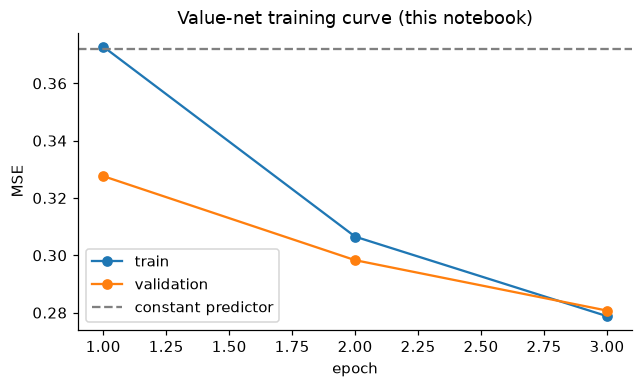

,epoch,train_loss,val_loss
0,1,0.373,0.328
1,2,0.307,0.298
2,3,0.279,0.281


In [7]:
log_path = resolve("src/model/checkpoints/train_log.csv")
log = pd.DataFrame(history) if history else (pd.read_csv(log_path) if log_path.exists() else None)
if log is not None:
    plt.figure(figsize=(6.5, 3.5))
    plt.plot(log.epoch, log.train_loss, marker="o", label="train")
    plt.plot(log.epoch, log.val_loss, marker="o", label="validation")
    plt.axhline(baseline, ls="--", c="grey", label="constant predictor")
    plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Value-net training curve" + (" (this notebook)" if history else " (logged run)"))
    plt.legend(); plt.show()
    display(log.tail(5))

### 2.2 How good is the value network?

Checks from `scripts/check_value_net.py`, on the validation positions: MSE against the baseline, sign accuracy (draws excluded), Spearman correlation with Stockfish's evaluation, and sanity positions.

In [8]:
from scipy.stats import spearmanr

pred = predict(value_net, va["planes"])
mse = float(np.mean((pred - y_va) ** 2))
mask = va["y"] != 0
sign_acc = float(np.mean(np.sign(pred[mask]) == np.sign(va["y"][mask])))
rows = [("validation MSE", mse), ("constant-predictor MSE", baseline), ("sign accuracy, draws excluded", sign_acc)]
if "sf_cp_white" in va:
    rows.append(("Spearman with tanh(Stockfish cp/400)", float(spearmanr(pred, np.tanh(va["sf_cp_white"] / 400)).statistic)))
display(pd.DataFrame(rows, columns=["metric", "value"]))

vf = make_value_fn(value_net, DEVICE)
sanity = {"start position": chess.STARTING_FEN,
          "White a queen up": "rnb1kbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQKBNR w KQkq - 0 1",
          "Black a queen up": "rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNB1KBNR w KQkq - 0 1",
          "White a rook up (endgame)": "4k3/pp6/8/8/8/8/PP6/R3K3 w - - 0 1"}
display(pd.DataFrame([(k, round(vf(chess.Board(f)), 3)) for k, f in sanity.items()], columns=["position", "value (White's view)"]))

,metric,value
0,validation MSE,0.281
1,constant-predictor MSE,0.372
2,"sign accuracy, draws excluded",0.640
3,Spearman with tanh(Stockfish cp/400),0.557


,position,value (White's view)
0,start position,0.046
1,White a queen up,0.027
2,Black a queen up,0.058
3,White a rook up (endgame),0.521


### 2.3 The "dead layer" problem (V1) and the V2 fix

If every unit of the 256-unit hidden layer is ≤ 0 after ReLU, the output no longer depends on the position: the network returns a constant. We measure that with a forward hook, for the V1 and V2 checkpoints.

In [9]:
@torch.no_grad()
def dead_rate(model, packed, bs=2048):
    acts = []
    h = model.head[4].register_forward_hook(lambda m, i, o: acts.append((o <= 0).all(dim=1).cpu()))
    predict(model, packed, bs); h.remove()
    return float(torch.cat(acts).float().mean())

nets = {"V1 net (ReLU, outcome labels)": resolve(CFG["v2"]["v1_checkpoint"]), "V2 net (LeakyReLU, blended labels)": FROZEN_CKPT}
rows = []
for name, path in nets.items():
    if path.exists():
        m = load_checkpoint(path, DEVICE)
        p = predict(m, va["planes"])
        vals, counts = np.unique(np.round(p, 5), return_counts=True)
        rows.append({"network": name, "all-hidden-units-off rate": dead_rate(m, va["planes"]),
                     "constant-output rate": counts.max() / len(p),
                     "Spearman vs Stockfish": float(spearmanr(p, np.tanh(va["sf_cp_white"] / 400)).statistic) if "sf_cp_white" in va else np.nan})
display(pd.DataFrame(rows))
print("With LeakyReLU, 'all units negative' no longer means a constant output, which is why the constant-output rate is the measure that matters.")

,network,all-hidden-units-off rate,constant-output rate,Spearman vs Stockfish
0,"V1 net (ReLU, outcome labels)",0.080,8.049e-02,0.619
1,"V2 net (LeakyReLU, blended labels)",0.013,2.000e-04,0.665


With LeakyReLU, 'all units negative' no longer means a constant output, which is why the constant-output rate is the measure that matters.


## 3. System 1: LayaChess

LayaChess (`datafreak/laya-chess`, about 421M parameters) is **reused, not trained by us**. For a position it runs one forward pass **per legal move** and returns, for each move, the win chance of the side to move after it (between 0.05 and 0.95). `LayaAgent` (`src/engine/LayaAgent.py`) wraps it, times it, and computes a **confidence** from the scores. V1 chose `top1_softmax` at T = 0.5 on validation data: the largest probability of a softmax over the win-chance logits.

`Resources` loads Laya, the value nets and the tablebases **once** and shares them between agents (loading Laya several times ran out of memory).

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

[laya-chess] datafreak/laya-chess (final, step 32000, 2,048,000 examples) on cuda/float16 in 3.0s


,move,win chance
0,Qxf7#,0.943
1,Qe2,0.327
2,Qd1,0.323
3,Qf3,0.320
4,Qg5,0.275
5,Qh4,0.263


Laya's best: Qxf7# | confidence (top1_softmax, T=0.5): 0.995 | 43 moves scored in 1463 ms


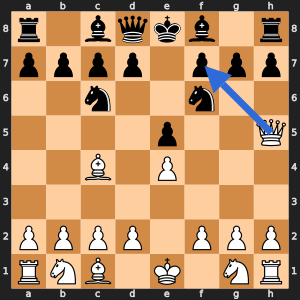

In [10]:
from src.engine.factory import Resources, build_agent

RES = Resources(CFG, load_gate_config())
laya = RES.laya
pos = chess.Board("r1bqkb1r/pppp1ppp/2n2n2/4p2Q/2B1P3/8/PPPP1PPP/RNB1K1NR w KQkq - 4 4")   # Scholar's-mate pattern: Qxf7# wins
out = laya.evaluate(pos)
top = sorted(out.scores.items(), key=lambda kv: -kv[1])[:6]
display(pd.DataFrame([(pos.san(m), round(w, 3)) for m, w in top], columns=["move", "win chance"]))
print(f"Laya's best: {pos.san(out.best_move)} | confidence ({laya.confidence_name}, T={laya.temperature}): {out.confidence:.3f} | "
      f"{out.n_scored} moves scored in {out.elapsed_ms:.0f} ms")
show(pos, [chess.svg.Arrow(out.best_move.from_square, out.best_move.to_square, color="#2F6BD8")])

## 4. System 2: PUCT tree search

`SearchTree` (`src/mcts/SearchTree.py`) is AlphaZero-style Monte Carlo tree search **without random playouts**: the value network scores each new leaf. Each simulation:

1. **Select** from the root, always taking the move with the highest score $Q(a) + c_{puct} \cdot P(a) \cdot \frac{\sqrt{N}}{1 + n(a)}$: value so far, plus a bonus for moves with a high prior P that were tried rarely
2. **Expand** the new position
3. **Evaluate** it: exact result if the game is over, else the value net (converted to the side to move, the only place that conversion happens)
4. **Back up** the value, flipping its sign at every ply

The prior P at the root comes from Laya's win chances (softmax of logits ÷ `prior_temperature`). V2 adds tactical priors inside the tree, a quiescence correction at the leaves, and tablebase leaves (`make_search_factory`). The move played is the one **visited most**.

In [11]:
from src.engine.AgentV2 import make_search_factory

pos = chess.Board("r2q1rk1/pp2bppp/2n1bn2/3p4/3P4/2NBBN2/PP3PPP/R2Q1RK1 w - - 4 11")   # a quiet middlegame
out = laya.evaluate(pos)
tree = make_search_factory(RES.value_fn, CFG, RES.tablebase, improved=True)(400)
t0 = time.time()
res = tree.search(pos, root_scores=out.scores)
print(f"{res.sims} simulations in {time.time() - t0:.2f}s, {res.cnn_evals} value-net calls, max depth {res.max_depth}")
tot = sum(res.visits.values())
tab = pd.DataFrame([(pos.san(m), n, n / tot, res.q.get(m, np.nan), out.scores[m]) for m, n in res.visits.items() if n > 0],
                   columns=["move", "visits", "share", "Q (mover's view)", "Laya win chance"]).sort_values("visits", ascending=False).head(8)
display(tab)
b = pos.copy(); pv = []
for m in res.pv:
    pv.append(b.san(m)); b.push(m)
print("expected line (principal variation):", " ".join(pv))
print("Laya's choice:", pos.san(out.best_move), "| search's choice:", pos.san(res.move))

[v2] tablebases: up to 5 pieces


400 simulations in 1.52s, 399 value-net calls, max depth 17


,move,visits,share,Q (mover's view),Laya win chance
18,Qc2,61,0.152,-0.023,0.495
14,Re1,46,0.115,-0.055,0.510
1,Ne5,41,0.102,-0.011,0.471
7,Bb5,34,0.085,-0.017,0.474
15,Qb3,19,0.048,-0.058,0.476
16,Qe2,17,0.043,-0.068,0.494
24,h3,12,0.030,-0.141,0.499
27,a3,12,0.030,-0.150,0.502


expected line (principal variation): Qc2 Kh8 Ng5 Kg8 Nxh7 Nxh7 Nxd5 Qxd5
Laya's choice: Re1 | search's choice: Qc2


### Why the prior temperature matters

With T = 0.01 (V1's value) a small difference in Laya's win chances becomes an enormous difference in prior, so the search barely looks at anything but Laya's favourite. With T = 0.1 (chosen on validation for V2) the search can disagree. A stale configuration that silently put 0.01 back invalidated the first V3 test run.

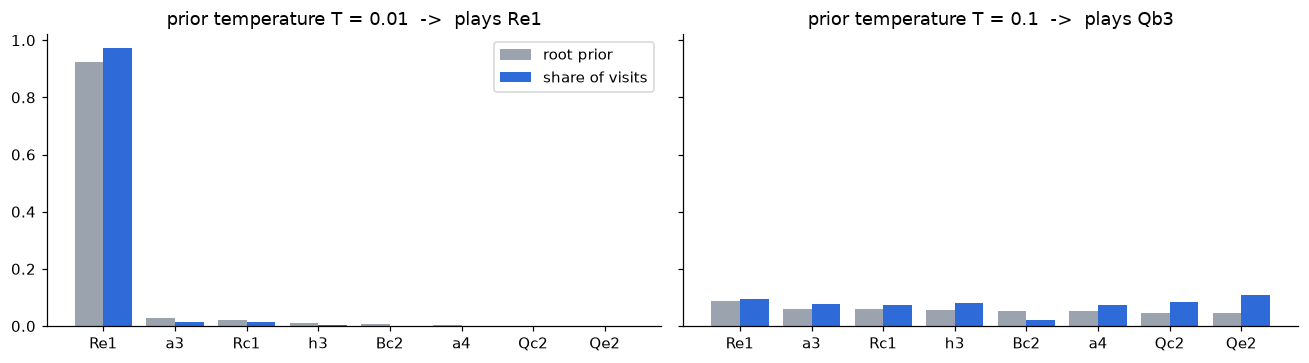

In [12]:
from src.mcts.SearchTree import SearchTree, root_prior

moves = sorted(out.scores, key=lambda m: -out.scores[m])[:8]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for a, T in zip(ax, (0.01, 0.1)):
    st = SearchTree(RES.value_fn, 400, CFG["mcts"]["c_puct"], CFG["mcts"]["fpu_reduction"], T)
    r = st.search(pos, root_scores=out.scores)
    share = [r.visits.get(m, 0) / 400 for m in moves]
    prior = root_prior(list(pos.legal_moves), out.scores, T)
    pr = dict(zip(pos.legal_moves, prior))
    xs = np.arange(len(moves))
    a.bar(xs - 0.2, [pr[m] for m in moves], 0.4, label="root prior", color="#9AA3AE")
    a.bar(xs + 0.2, share, 0.4, label="share of visits", color="#2F6BD8")
    a.set_xticks(xs, [pos.san(m) for m in moves]); a.set_title(f"prior temperature T = {T}  ->  plays {pos.san(r.move)}")
ax[0].legend(); plt.tight_layout(); plt.show()

## 5. The V2 safety net

The change that made V2 strong uses **no neural network**: a small classical search that counts only material (pawn 100, knight 320, bishop 330, rook 500, queen 900). `tactical_score` plays a move, searches 2 plies full width with alpha-beta, then follows captures until the position is quiet (quiescence search). `safe_choice` keeps the preferred move unless it loses more than 150 cp compared with the best alternative; then it plays the most preferred move among the top 6 that is safe.

Example: the queen move Qd5 walks into …exd5. A move list that prefers it gets vetoed.

material now: 800 cp
tactical score of Qd5: -100 cp   |   of Qd3: 800 cp
preferred Qd5 -> safety net plays Qd3 (overridden = True)


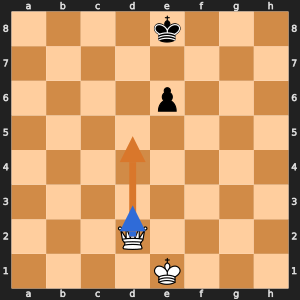

In [13]:
from src.engine.tactics import safe_choice, tactical_score, material

b = chess.Board("4k3/8/4p3/8/8/8/3Q4/4K3 w - - 0 1")
blunder, ok = chess.Move.from_uci("d2d5"), chess.Move.from_uci("d2d3")
preference = [blunder, ok] + [m for m in b.legal_moves if m not in (blunder, ok)]
r = safe_choice(b, preference)
print(f"material now: {material(b, chess.WHITE)} cp")
print(f"tactical score of {b.san(blunder)}: {tactical_score(b, blunder)} cp   |   of {b.san(ok)}: {tactical_score(b, ok)} cp")
print(f"preferred {b.san(blunder)} -> safety net plays {b.san(r.move)} (overridden = {r.overridden})")
show(b, [chess.svg.Arrow(blunder.from_square, blunder.to_square, color="#D9772B"), chess.svg.Arrow(r.move.from_square, r.move.to_square, color="#2F6BD8")])

## 6. The gates: when to search

| Version | Gate | Code |
|---|---|---|
| V1 | search if Laya's confidence ≤ τ; τ set from validation quantiles for 10/25/50/75% search | `src/engine/gating.py`, `configs/gate_frozen.yaml` |
| V2 | search if the position is **critical**: in check, a piece hanging, a profitable capture, ≤ 12 legal moves, or endgame | `tactics.criticality` |
| V3 | logistic regression on 18 pre-search features predicts whether search will improve the move | `src/engine/gate_features.py`, `configs/gate_learned.json` |

V1 gate: top1_softmax (T=0.5), thresholds tau: {'0.10': 0.048394673677494206, '0.25': 0.057581822578711174, '0.50': 0.08405002391600905, '0.75': 0.1713213093269189}


,position,V1 confidence,V1 search at 50%?,V2 critical?,flags,V3 score,V3 search (25%)?
0,quiet middlegame,0.036,True,False,,-0.544,False
1,queen attacked by a rook,0.487,False,True,"hanging, opportunity, endgame",-3.392,False
2,rook endgame,0.345,False,True,"hanging, opportunity, endgame",-6.183,False


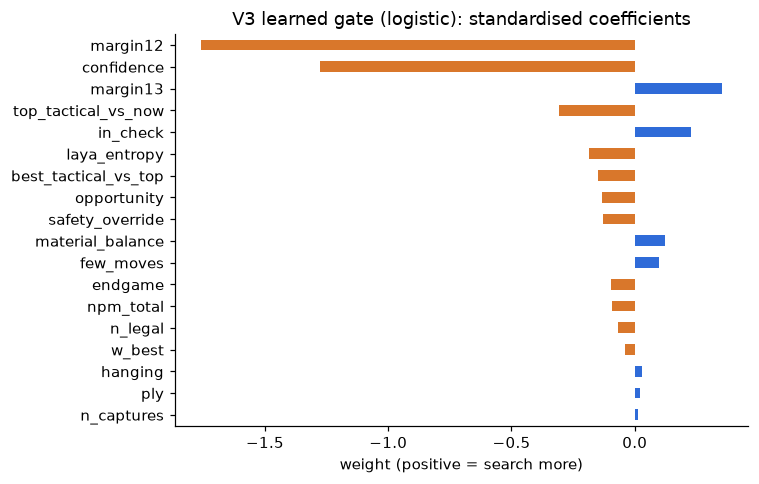

In [14]:
from src.engine.tactics import criticality
from src.engine.gate_features import gate_features, LearnedGate, FEATURES

gcfg = load_gate_config()
if gcfg:
    print(f"V1 gate: {gcfg['confidence']} (T={gcfg['temperature']}), thresholds tau: {gcfg['tau']}")

examples = {"quiet middlegame": pos.fen(),
            "queen attacked by a rook": "4k3/8/8/8/8/8/3r4/3QK3 w - - 0 1",
            "rook endgame": "8/5k2/8/3R4/8/8/5K2/3r4 w - - 0 1"}
lg = LearnedGate(resolve(CFG["v2"]["learned_gate_path"]), 25)
rows = []
for name, fen in examples.items():
    bb = chess.Board(fen); o = laya.evaluate(bb); c = criticality(bb)
    f = gate_features(bb, o.scores, o.confidence)
    rows.append({"position": name, "V1 confidence": round(o.confidence, 3),
                 "V1 search at 50%?": o.confidence <= float(gcfg["tau"]["0.50"]) if gcfg else None,
                 "V2 critical?": c.critical, "flags": ", ".join(k for k in ("in_check", "hanging", "opportunity", "few_moves", "endgame") if getattr(c, k)),
                 "V3 score": round(lg.score(f), 3), "V3 search (25%)?": lg.use_search(f)})
display(pd.DataFrame(rows))

g = json.loads(resolve(CFG["v2"]["learned_gate_path"]).read_text())
coef = pd.Series(g["coef"], index=g["features"]).sort_values(key=abs, ascending=False)
plt.figure(figsize=(7, 4.5)); coef.iloc[::-1].plot.barh(color=["#2F6BD8" if v > 0 else "#D9772B" for v in coef.iloc[::-1]])
plt.title(f"V3 learned gate ({g['model']}): standardised coefficients"); plt.xlabel("weight (positive = search more)"); plt.tight_layout(); plt.show()

## 7. The full agent playing a game

`V2Agent.decide` (`src/engine/AgentV2.py`) runs the layers in order: tablebase → mate in one → Laya → gate → search → contempt (avoid repeating a position when ahead) → safety net. `factory.build_agent` builds any agent by name. Here `v3_learned_25` (the V3 agent) plays 40 plies against Stockfish limited to Elo 1320, starting from one of the fixed V3 test openings. Every move logs which system decided, whether the gate fired and whether the safety net overrode.

,ply,side,move,system,gate fired,safety override,ms
0,8,v3_learned_25,e3,search,1,0,1757
2,10,v3_learned_25,dxc5,search,0,0,1223
4,12,v3_learned_25,cxd5,Laya,1,0,499
6,14,v3_learned_25,dxe6,Laya,0,0,483
8,16,v3_learned_25,Qxd8+,Laya,0,0,469
10,18,v3_learned_25,Bc4,Laya,0,0,424
12,20,v3_learned_25,Bb3,search,0,0,1107
14,22,v3_learned_25,axb3,Laya,1,0,322
16,24,v3_learned_25,O-O,Laya,0,0,418
18,26,v3_learned_25,e4,search,0,0,1086


result so far: * | our agent searched on 45% of its moves


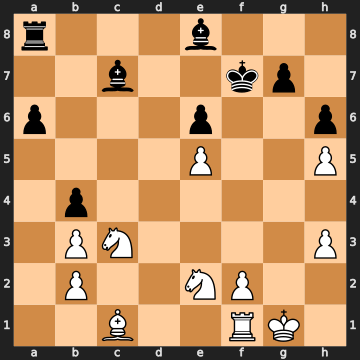

In [15]:
AGENT, OPPONENT, PLIES = "v3_learned_25", "sf_elo_1320", 40
bot, sf = build_agent(AGENT, RES), build_agent(OPPONENT, RES)
openings = pd.read_csv(resolve(CFG["data"]["benchmark_dir"]) / "openings.csv")
game_board = chess.Board()
for u in openings.uci_moves.iloc[0].split():
    game_board.push_uci(u)
log = []
for _ in range(PLIES):
    if game_board.is_game_over(claim_draw=True):
        break
    mover = bot if game_board.turn == chess.WHITE else sf
    mv, info = mover.select_move(game_board.copy())
    d = info.as_dict()
    log.append({"ply": game_board.ply(), "side": mover.name, "move": game_board.san(mv),
                "system": {0: "Stockfish", 1: "Laya", 2: "search", 3: "tablebase/mate"}[d["system"]],
                "gate fired": d.get("critical", ""), "safety override": d.get("safety_override", ""), "ms": round(d["time_elapsed_ms"])})
    game_board.push(mv)
moves_df = pd.DataFrame(log)
display(moves_df[moves_df.side == AGENT].head(20))
print("result so far:", game_board.result(claim_draw=True), "| our agent searched on",
      f"{(moves_df[moves_df.side == AGENT].system == 'search').mean():.0%} of its moves")
show(game_board, size=360)

## 8. Results of the three versions

Everything below is recomputed from the raw result files in `data/results/`: one row per judged move for the position benchmarks (Study A), one row per game for the tournaments. **CPL** = centipawn loss against full-strength Stockfish (200k nodes); **ACPL** = its average; **blunder** = CPL ≥ 200.

In [16]:
R = resolve(CFG["results_dir"])
studies = {"V1 (test 2025-11)": "bench_test", "V2 (test 2025-03)": "v2_bench", "V3 (test 2025-02)": "v3_bench"}
tables = {}
for label, run in studies.items():
    f = R / run / "benchmark_moves.csv"
    if not f.exists():
        print("missing:", f); continue
    bm = pd.read_csv(f)
    bm["blunder"] = bm.cpl >= 200
    t = bm.groupby("agent").agg(positions=("pos_id", "nunique"), ACPL=("cpl", "mean"), blunder_rate=("blunder", "mean"),
                                 sec_per_move=("wall_ms", lambda s: s.mean() / 1000))
    tables[label] = t.sort_values("ACPL", ascending=False)
    print(label); display(tables[label])

V1 (test 2025-11)


,positions,ACPL,blunder_rate,sec_per_move
agent,,,,
mcts_uniform,3000,235.409,0.424,1.042
laya_only,3000,107.855,0.173,0.468
always_s2,3000,103.065,0.166,1.499


V2 (test 2025-03)


,positions,ACPL,blunder_rate,sec_per_move
agent,,,,
laya_only,2000,114.534,0.177,0.476
v2_safe,2000,76.468,0.115,0.571
v2_full_oldnet,2000,69.711,0.097,1.166
v2_full,2000,68.668,0.096,1.308
v2_always,2000,65.386,0.092,1.604


V3 (test 2025-02)


,positions,ACPL,blunder_rate,sec_per_move
agent,,,,
laya_only,2000,111.775,0.174,0.386
v2_safe,2000,76.603,0.114,0.487
v2_full,2000,67.373,0.097,1.204
v2_always,2000,64.927,0.093,1.484
v3_look4,2000,64.451,0.090,1.864


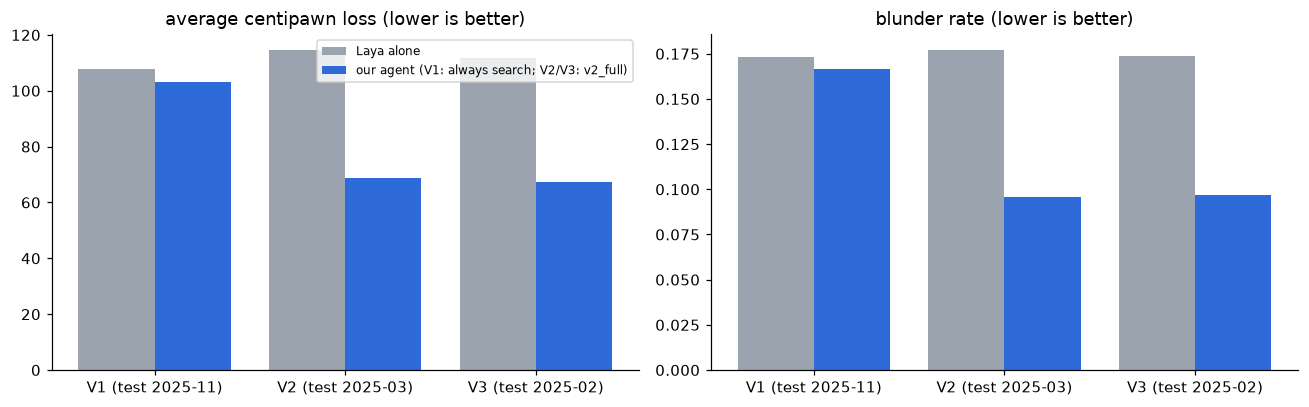

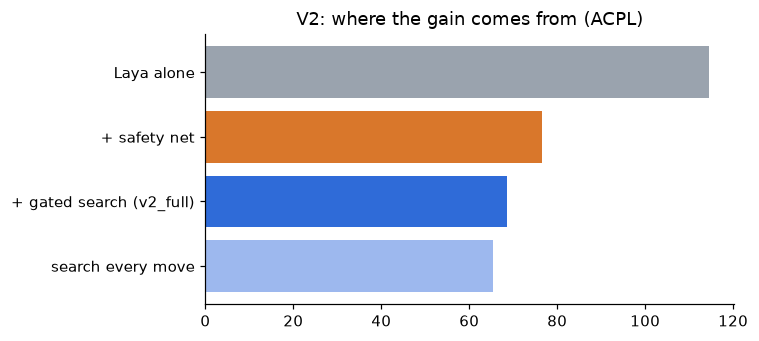

In [17]:
pairs = {"V1 (test 2025-11)": ("laya_only", "always_s2"), "V2 (test 2025-03)": ("laya_only", "v2_full"), "V3 (test 2025-02)": ("laya_only", "v2_full")}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
labels_ = [l for l in pairs if l in tables]
x = np.arange(len(labels_))
for j, (metric, title) in enumerate((("ACPL", "average centipawn loss"), ("blunder_rate", "blunder rate"))):
    base = [tables[l].loc[pairs[l][0], metric] for l in labels_]
    full = [tables[l].loc[pairs[l][1], metric] for l in labels_]
    ax[j].bar(x - 0.2, base, 0.4, label="Laya alone", color="#9AA3AE")
    ax[j].bar(x + 0.2, full, 0.4, label="our agent (V1: always search; V2/V3: v2_full)", color="#2F6BD8")
    ax[j].set_xticks(x, labels_); ax[j].set_title(title + " (lower is better)")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

if "V2 (test 2025-03)" in tables:
    t = tables["V2 (test 2025-03)"]
    steps = [a for a in ("laya_only", "v2_safe", "v2_full", "v2_always") if a in t.index]
    plt.figure(figsize=(7, 3.2))
    plt.barh(["Laya alone", "+ safety net", "+ gated search (v2_full)", "search every move"][:len(steps)][::-1],
             [t.loc[a, "ACPL"] for a in steps][::-1], color=["#9DB8EE", "#2F6BD8", "#D9772B", "#9AA3AE"][-len(steps):])
    plt.title("V2: where the gain comes from (ACPL)"); plt.tight_layout(); plt.show()

### Elo from the tournaments

Each agent played fixed openings with both colours against Stockfish limited to a nominal Elo (1320 in V1/V2; 1320 and 1600 in V3). `src/eval/elo.py` fits a **Bradley–Terry** model with the anchors fixed and gets 95% intervals by resampling openings (both colours of an opening together). The paper used 1000 resamples; 300 here to keep it quick.

V1: 500 games


,agent,elo,ci_low,ci_high,games,score,anchor,off_scale
0,sf_elo_1320,1320.0,1320.0,1320.0,200,0.935,True,False
1,laya_only,904.2,829.3,956.2,200,0.468,False,False
2,always_s2,887.3,817.0,936.9,200,0.443,False,True
3,hybrid_s2_50,878.9,800.0,928.2,200,0.430,False,True
4,mcts_uniform,734.1,668.5,787.9,200,0.225,False,True


V2: 600 games


,agent,elo,ci_low,ci_high,games,score,anchor,off_scale
0,sf_elo_1320,1320.0,1320.0,1320.0,500,0.794,True,False
1,v2_full_oldnet,1168.9,1090.3,1235.1,100,0.295,False,False
2,v2_full,1129.6,1074.0,1180.7,200,0.505,False,False
3,v2_full_nosafety,1079.6,1005.4,1147.5,100,0.200,False,False
4,v2_safe,1068.6,1008.8,1129.4,100,0.190,False,False
5,laya_only,929.5,867.3,991.0,200,0.168,False,True


V3: 800 games


,agent,elo,ci_low,ci_high,games,score,anchor,off_scale
0,sf_elo_1600,1600.0,1600.0,1600.0,400,0.905,True,False
1,sf_elo_1320,1320.0,1320.0,1320.0,400,0.829,True,False
2,v2_full,1191.8,1146.7,1229.2,200,0.205,False,False
3,v3_learned_25,1188.8,1127.9,1249.9,200,0.203,False,False
4,classical_full,979.5,912.1,1038.7,200,0.075,False,False
5,laya_only,903.1,824.9,963.0,200,0.050,False,True


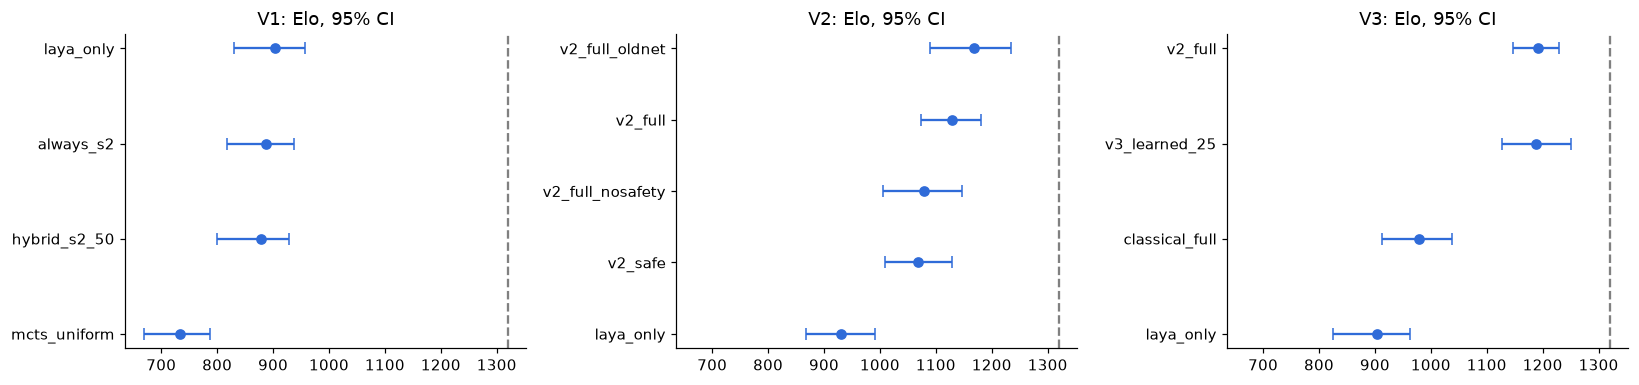

In [18]:
from src.eval.elo import bootstrap_ratings, anchor_elos

tours = {"V1": ["tour_1", "tour_t2a", "tour_t2b"], "V2": ["v2_tour_a", "v2_tour_b"], "V3": ["v3_tour_a", "v3_tour_b"]}
elo_tables = {}
for v, runs in tours.items():
    files = [R / r / "games.csv" for r in runs if (R / r / "games.csv").exists()]
    if not files:
        print("missing tournament files for", v); continue
    games = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    names = sorted(set(games.white) | set(games.black))
    elo_tables[v] = bootstrap_ratings(games, anchor_elos(names), n=300, seed=CFG["seed"])
    print(f"{v}: {len(games)} games"); display(elo_tables[v])

if elo_tables:
    fig, axes = plt.subplots(1, len(elo_tables), figsize=(5 * len(elo_tables), 3.6), sharex=True)
    axes = np.atleast_1d(axes)
    for a, (v, t) in zip(axes, elo_tables.items()):
        t = t[~t.anchor].sort_values("elo")
        a.errorbar(t.elo, range(len(t)), xerr=[t.elo - t.ci_low, t.ci_high - t.elo], fmt="o", color="#2F6BD8", capsize=4)
        a.set_yticks(range(len(t)), t.agent); a.set_title(f"{v}: Elo, 95% CI"); a.axvline(1320, ls="--", c="grey")
    plt.tight_layout(); plt.show()

### V3: does the learned gate beat a random gate?

The frozen gate is evaluated on the untouched V3 month by exact offline composition: take `v2_always`'s move where the gate fires and `v2_safe`'s move elsewhere, and compare with a random gate searching the same share of positions (paired bootstrap, 4000 resamples). This is the pre-registered primary test (`scripts/train_gate.py --eval`).

TEST evaluation of the frozen gate (logistic), n=2000
never 76.60  always 64.93  critical gate (58.7%) 67.37
 rate_pct  achieved_rate  learned_acpl  random_acpl_expected  random_minus_learned  ci_lo  ci_hi  p_one_sided  oracle_acpl
       10          0.100        74.100                75.435                 1.324 -1.195  3.866        0.149       57.133
       25          0.258        71.116                73.597                 2.492 -0.864  5.840        0.069       53.384
       60          0.598        66.414                69.627                 3.203  0.085  6.675        0.022       53.384
random_minus_learned > 0 with CI above 0 = the learned gate beats a random gate at the same rate



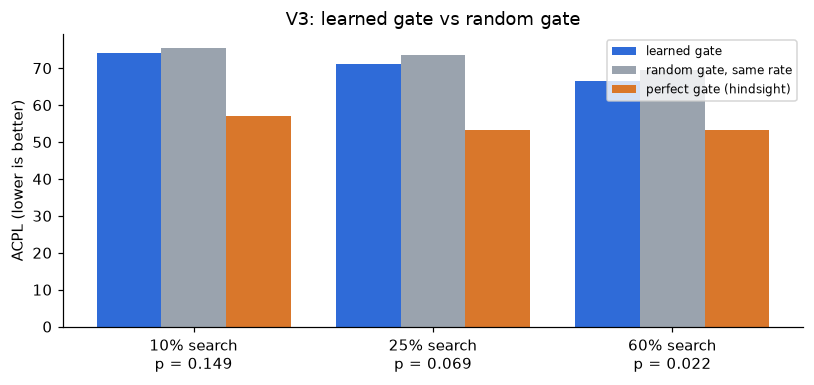

In [19]:
cmd = [sys.executable, "-m", "scripts.train_gate", "--config", "configs/v3.yaml", "--eval", "--bench-run", "v3_bench", "--features-run", "v3_bench"]
if (R / "v3_bench" / "gate_features.csv").exists():
    print(subprocess.run(cmd, capture_output=True, text=True, cwd=ROOT).stdout)
    gt = pd.read_csv(resolve("paper/figures/V3_gate_test.csv"))
    x = np.arange(len(gt))
    plt.figure(figsize=(7.5, 3.6))
    for k, (col, lab, colr) in enumerate((("learned_acpl", "learned gate", "#2F6BD8"), ("random_acpl_expected", "random gate, same rate", "#9AA3AE"), ("oracle_acpl", "perfect gate (hindsight)", "#D9772B"))):
        plt.bar(x + (k - 1) * 0.27, gt[col], 0.27, label=lab, color=colr)
    plt.xticks(x, [f"{r}% search\np = {p:.3f}" for r, p in zip(gt.rate_pct, gt.p_one_sided)]); plt.ylabel("ACPL (lower is better)")
    plt.legend(fontsize=8); plt.title("V3: learned gate vs random gate"); plt.tight_layout(); plt.show()
else:
    print("v3_bench/gate_features.csv not found")

In [20]:
RES.close()     # stop the Stockfish processes

## 9. Conclusions

| | V1 | V2 | V3 |
|---|---|---|---|
| Gate | Laya's confidence | sharp-position rules | learned logistic model |
| Gate vs random gate | −0.09 cp (no better) | +1.1 cp (no better) | +2.5 cp at 25%, p = 0.069 (not significant) |
| ACPL, Laya → agent | 107.9 → 103.1 | 114.5 → 68.7 | 111.8 → 67.4 |
| Blunders, Laya → agent | 17.3% → 16.6% | 17.7% → 9.6% | 17.4% → 9.7% |
| Elo, Laya → agent | 904 → 879 | 930 → 1130 | 903 → 1192 |

- **The strength came from not hanging pieces.** The material safety net gave most of V2's gain; V2's +289 Elo over Laya replicated on a new month with two anchors.
- **Laya matters:** the same safety net and search with a hand-written policy instead of Laya lost 212 Elo.
- **When to think is still unsolved:** three different gates, none significantly better than a random gate at the same search rate; a perfect gate would reach ACPL 53 against our 71.
- **Limitations:** anchor Elo is nominal (limited Stockfish at 100 ms per move); 100–200 games per agent; the safety net sees material only; overlap between Laya's training data and our test games was not checked; the learned gate searched 40% of moves in games instead of the 25% it was tuned for.